# MedInsight Analytics — Realistic Dataset Generation

## Hybrid data strategy | 100,000 synthetic appointments | Sri Lanka-inspired demonstration

This notebook creates a **synthetic hospital operations dataset** with linked tables. It is designed for portfolio development and operational simulation, not to represent actual hospital records or actual Sri Lankan hospital statistics.

**Data separation is deliberate:**
- Synthetic operational data is saved under `data/raw/synthetic/`.
- The optional public Brazil no-show dataset is kept under `data/raw/real/` and processed separately.
- Never combine synthetic rows with real rows or describe simulated values as observed hospital facts.

**What improves on the first notebook:** stable patient profiles; unequal demand; branch and department relationships; doctor schedules and capacity; no Sunday appointments; lead-time and attendance patterns; queue-derived waiting time; separate payment and satisfaction records; relational and statistical validation.

> All hospital counts, branch shares, tariffs, schedules and behavioural probabilities below are **explicit simulation assumptions**. Replace them with approved local data if available.

## 1. Imports and reproducibility

Run the notebook from the project root or from the `notebooks/` folder. A fixed seed makes the same synthetic dataset reproducible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import json
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
print("Libraries loaded. Seed:", RANDOM_SEED)

Libraries loaded. Seed: 42


## 2. Project paths and simulation settings

The output folders are intentionally separated by provenance. The default period is calendar year 2025, matching the original notebook, and the target is exactly 100,000 appointment bookings.

In [2]:
# Find the project root whether the notebook is opened from root or notebooks/
CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

NUM_APPOINTMENTS = 100_000
NUM_PATIENTS = 25_000
START_DATE = "2025-01-01"
END_DATE = "2025-12-31"

SYNTHETIC_DIR = PROJECT_ROOT / "data" / "raw" / "synthetic"
REAL_DIR = PROJECT_ROOT / "data" / "raw" / "real"
PROCESSED_REAL_DIR = PROJECT_ROOT / "data" / "processed" / "real"
for folder in [SYNTHETIC_DIR, REAL_DIR, PROCESSED_REAL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Synthetic appointments target:", NUM_APPOINTMENTS)
print("Synthetic output:", SYNTHETIC_DIR)
print("Real data input (kept separate):", REAL_DIR)

Project root: /Users/nethulinatharadhanapala/MedInsight-Analytics
Synthetic appointments target: 100000
Synthetic output: /Users/nethulinatharadhanapala/MedInsight-Analytics/data/raw/synthetic
Real data input (kept separate): /Users/nethulinatharadhanapala/MedInsight-Analytics/data/raw/real


## 3. Define the hospital reference tables

The example network has four branches, eight departments and 32 doctors (one doctor for each branch-department combination). Department demand and branch volumes are intentionally unequal. These percentages are **chosen assumptions for simulation**, not market research or real hospital statistics.

In [3]:
branches_df = pd.DataFrame([
    {"branch_id": "BR01", "branch_name": "Colombo", "branch_demand_weight": 0.46, "timezone": "Asia/Colombo"},
    {"branch_id": "BR02", "branch_name": "Kandy",   "branch_demand_weight": 0.22, "timezone": "Asia/Colombo"},
    {"branch_id": "BR03", "branch_name": "Galle",   "branch_demand_weight": 0.18, "timezone": "Asia/Colombo"},
    {"branch_id": "BR04", "branch_name": "Negombo", "branch_demand_weight": 0.14, "timezone": "Asia/Colombo"},
])

departments_df = pd.DataFrame([
    ["DEP01", "General Medicine", 0.24, 20, 2500, 4500],
    ["DEP02", "Cardiology",       0.17, 30, 4000, 8500],
    ["DEP03", "Pediatrics",       0.15, 20, 2500, 5000],
    ["DEP04", "Orthopedics",      0.12, 25, 3500, 7500],
    ["DEP05", "Dermatology",      0.10, 15, 2000, 5000],
    ["DEP06", "Neurology",        0.08, 30, 4000, 9000],
    ["DEP07", "ENT",              0.07, 20, 2500, 5500],
    ["DEP08", "Gastroenterology", 0.07, 25, 3500, 8000],
], columns=["department_id", "department_name", "demand_weight", "standard_duration_min", "tariff_min_lkr", "tariff_max_lkr"])

assert np.isclose(branches_df.branch_demand_weight.sum(), 1.0)
assert np.isclose(departments_df.demand_weight.sum(), 1.0)
display(branches_df)
display(departments_df)

,branch_id,branch_name,branch_demand_weight,timezone
0,BR01,Colombo,0.46,Asia/Colombo
1,BR02,Kandy,0.22,Asia/Colombo
2,BR03,Galle,0.18,Asia/Colombo
3,BR04,Negombo,0.14,Asia/Colombo


,department_id,department_name,demand_weight,standard_duration_min,tariff_min_lkr,tariff_max_lkr
0,DEP01,General Medicine,0.24,20,2500,4500
1,DEP02,Cardiology,0.17,30,4000,8500
2,DEP03,Pediatrics,0.15,20,2500,5000
3,DEP04,Orthopedics,0.12,25,3500,7500
4,DEP05,Dermatology,0.10,15,2000,5000
5,DEP06,Neurology,0.08,30,4000,9000
6,DEP07,ENT,0.07,20,2500,5500
7,DEP08,Gastroenterology,0.07,25,3500,8000


## 4. Generate stable patient profiles

A patient has one permanent ID, age, gender and home branch in the patient dimension table. Repeat appointments reference that same patient ID, so demographics do not randomly change from visit to visit. Visit frequency is uneven: most patients book once, while a smaller group returns multiple times.

In [4]:
patient_ids = np.array([f"PAT{i:06d}" for i in range(1, NUM_PATIENTS + 1)])
# Broad age distribution: a mixture creates children, working-age adults and older adults.
age_component = rng.choice(["child", "adult", "older"], NUM_PATIENTS, p=[0.18, 0.62, 0.20])
ages = np.empty(NUM_PATIENTS, dtype=int)
ages[age_component == "child"] = rng.integers(0, 18, (age_component == "child").sum())
ages[age_component == "adult"] = np.clip(rng.normal(39, 12, (age_component == "adult").sum()).round(), 18, 64).astype(int)
ages[age_component == "older"] = np.clip(rng.normal(72, 7, (age_component == "older").sum()).round(), 65, 95).astype(int)

genders = rng.choice(["Female", "Male", "Other / Prefer not to say"], NUM_PATIENTS, p=[0.51, 0.47, 0.02])
home_branch = rng.choice(branches_df.branch_id, NUM_PATIENTS, p=branches_df.branch_demand_weight.to_numpy())
insurance = rng.choice(["Insured", "Self-pay"], NUM_PATIENTS, p=[0.38, 0.62])

patients_df = pd.DataFrame({
    "patient_id": patient_ids,
    "age": ages,
    "age_band": pd.cut(ages, [-1, 17, 34, 49, 64, 120], labels=["0-17", "18-34", "35-49", "50-64", "65+"]).astype(str),
    "gender": genders,
    "home_branch_id": home_branch,
    "insurance_type": insurance,
    "created_date": pd.to_datetime(rng.choice(pd.date_range("2022-01-01", START_DATE), NUM_PATIENTS)).date
})

# Patient visit propensity: many one-time visitors, fewer repeat visitors.
visit_weights = rng.lognormal(mean=0.0, sigma=0.75, size=NUM_PATIENTS)
visit_weights = visit_weights / visit_weights.sum()
print("Patients:", len(patients_df), "| Unique patient IDs:", patients_df.patient_id.nunique())
display(patients_df.head())

Patients: 25000 | Unique patient IDs: 25000


,patient_id,age,age_band,gender,home_branch_id,insurance_type,created_date
0,PAT000001,23,18-34,Male,BR01,Insured,2022-09-20
1,PAT000002,43,35-49,Male,BR02,Self-pay,2023-04-17
2,PAT000003,65,65+,Female,BR02,Insured,2022-07-26
3,PAT000004,44,35-49,Male,BR03,Insured,2024-07-11
4,PAT000005,1,0-17,Male,BR02,Self-pay,2022-12-12


## 5. Create doctors and their schedules

Each doctor belongs to one branch and one department. Working patterns vary: most work Monday–Friday and some also work Saturday. Sunday is closed in this simulation. Each doctor has a daily booking capacity represented by 30-minute appointment slots; Saturday sessions are shorter.

In [5]:
doctor_rows = []
for _, br in branches_df.iterrows():
    for _, dep in departments_df.iterrows():
        for n in range(1, 2):
            doctor_rows.append({
                "doctor_id": f"DOC{len(doctor_rows)+1:03d}",
                "doctor_name": f"Dr. {dep.department_name.split()[0]} {br.branch_name} {n}",
                "branch_id": br.branch_id,
                "department_id": dep.department_id,
                "years_experience": int(np.clip(rng.normal(11, 5), 1, 30)),
                "employment_status": "Active"
            })
doctors_df = pd.DataFrame(doctor_rows)

# Schedule dimension: one row per doctor per working date, plus the available time slots.
all_dates = pd.date_range(START_DATE, END_DATE, freq="D")
public_holidays = pd.to_datetime(["2025-01-14", "2025-02-04", "2025-04-13", "2025-04-14", "2025-05-01", "2025-12-25"])
schedule_rows = []
for d in all_dates:
    if d.dayofweek == 6 or d in public_holidays:
        continue
    for _, doc in doctors_df.iterrows():
        # Some doctors do not work Saturdays; this creates varied capacity.
        if d.dayofweek == 5 and rng.random() < 0.30:
            continue
        start_min = 8 * 60
        end_min = 13 * 60 if d.dayofweek == 5 else 16 * 60
        for minute in range(start_min, end_min, 30):
            schedule_rows.append((doc.doctor_id, doc.branch_id, doc.department_id, d, minute))

slots_df = pd.DataFrame(schedule_rows, columns=["doctor_id", "branch_id", "department_id", "appointment_date", "scheduled_minute"])
slots_df["scheduled_time"] = (slots_df.scheduled_minute // 60).astype(str).str.zfill(2) + ":" + (slots_df.scheduled_minute % 60).astype(str).str.zfill(2)
print("Doctors:", len(doctors_df), "| Available doctor-slots:", len(slots_df))
display(doctors_df.head())
display(slots_df.head())

Doctors: 32 | Available doctor-slots: 142692


,doctor_id,doctor_name,branch_id,department_id,years_experience,employment_status
0,DOC001,Dr. General Colombo 1,BR01,DEP01,7,Active
1,DOC002,Dr. Cardiology Colombo 1,BR01,DEP02,15,Active
2,DOC003,Dr. Pediatrics Colombo 1,BR01,DEP03,6,Active
3,DOC004,Dr. Orthopedics Colombo 1,BR01,DEP04,16,Active
4,DOC005,Dr. Dermatology Colombo 1,BR01,DEP05,10,Active


,doctor_id,branch_id,department_id,appointment_date,scheduled_minute,scheduled_time
0,DOC001,BR01,DEP01,2025-01-01,480,08:00
1,DOC001,BR01,DEP01,2025-01-01,510,08:30
2,DOC001,BR01,DEP01,2025-01-01,540,09:00
3,DOC001,BR01,DEP01,2025-01-01,570,09:30
4,DOC001,BR01,DEP01,2025-01-01,600,10:00


## 6. Build a realistic appointment-slot demand profile

We sample unique available doctor slots, not arbitrary date/doctor/time combinations. Slot selection is weighted by branch volume, department demand, weekday demand and time-of-day demand. This guarantees that no doctor is double-booked in the same 30-minute slot and prevents Sunday bookings.

In [6]:
# Join demand weights onto valid slots.
slot_pool = slots_df.merge(branches_df[["branch_id", "branch_demand_weight"]], on="branch_id", validate="many_to_one")
slot_pool = slot_pool.merge(departments_df[["department_id", "demand_weight"]], on="department_id", validate="many_to_one")
slot_pool["weekday"] = slot_pool.appointment_date.dt.dayofweek
weekday_weight = {0: 1.12, 1: 1.08, 2: 1.04, 3: 1.00, 4: 1.10, 5: 0.62}
slot_pool["weekday_weight"] = slot_pool.weekday.map(weekday_weight)
# Morning slots are busier; late-afternoon slots are less preferred.
slot_pool["time_weight"] = np.select(
    [slot_pool.scheduled_minute < 10*60, slot_pool.scheduled_minute < 13*60],
    [1.35, 1.00], default=0.72
)
slot_weights = (slot_pool.branch_demand_weight * slot_pool.demand_weight * slot_pool.weekday_weight * slot_pool.time_weight).to_numpy(dtype=float)
slot_weights = slot_weights / slot_weights.sum()

if len(slot_pool) < NUM_APPOINTMENTS:
    raise ValueError("Not enough available doctor slots for requested appointment count. Increase capacity or reduce target.")
selected_positions = rng.choice(len(slot_pool), size=NUM_APPOINTMENTS, replace=False, p=slot_weights)
appointments = slot_pool.iloc[selected_positions].copy().reset_index(drop=True)
appointments.insert(0, "appointment_id", [f"APT{i:07d}" for i in range(1, NUM_APPOINTMENTS + 1)])
appointments["weekday_name"] = appointments.appointment_date.dt.day_name()
appointments["month"] = appointments.appointment_date.dt.month
appointments["day_type"] = np.where(appointments.weekday.eq(5), "Saturday", "Weekday")

# Assign patients with unequal repeat-visit propensity.
appointments["patient_id"] = rng.choice(patient_ids, size=NUM_APPOINTMENTS, p=visit_weights)
appointments = appointments.merge(patients_df[["patient_id", "age", "gender", "insurance_type", "home_branch_id"]], on="patient_id", validate="many_to_one")
appointments["travel_branch_match"] = appointments.branch_id.eq(appointments.home_branch_id)

print("Generated appointment bookings:", len(appointments))
print("Unique patients with bookings:", appointments.patient_id.nunique())
print("Sunday bookings:", (appointments.appointment_date.dt.dayofweek == 6).sum())
display(appointments.head())

Generated appointment bookings: 100000
Unique patients with bookings: 22205
Sunday bookings: 0


,appointment_id,doctor_id,branch_id,department_id,appointment_date,scheduled_minute,scheduled_time,branch_demand_weight,demand_weight,weekday,weekday_weight,time_weight,weekday_name,month,day_type,patient_id,age,gender,insurance_type,home_branch_id,travel_branch_match
0,APT0000001,DOC009,BR02,DEP01,2025-07-18,540,09:00,0.22,0.24,4,1.10,1.35,Friday,7,Weekday,PAT005013,32,Female,Self-pay,BR04,False
1,APT0000002,DOC002,BR01,DEP02,2025-10-28,540,09:00,0.46,0.17,1,1.08,1.35,Tuesday,10,Weekday,PAT004165,41,Male,Self-pay,BR01,True
2,APT0000003,DOC026,BR04,DEP02,2025-10-14,540,09:00,0.14,0.17,1,1.08,1.35,Tuesday,10,Weekday,PAT009011,43,Male,Insured,BR02,False
3,APT0000004,DOC015,BR02,DEP07,2025-02-10,780,13:00,0.22,0.07,0,1.12,0.72,Monday,2,Weekday,PAT005615,22,Male,Insured,BR01,False
4,APT0000005,DOC017,BR03,DEP01,2025-12-19,630,10:30,0.18,0.24,4,1.10,1.00,Friday,12,Weekday,PAT012336,52,Female,Insured,BR01,False


## 7. Booking dates and appointment outcomes

Booking lead time is a mixture: same-day/short-notice bookings are common, while long lead times occur less often. No-show risk increases with longer lead time and is influenced by reminder receipt, previous attendance behaviour (simulated at patient level), age band and weekday. These are modelling assumptions, not clinical conclusions.

In [7]:
# Generate patient-level prior attendance tendency once, then reuse for all that patient's bookings.
patient_attendance_propensity = pd.Series(
    rng.beta(8, 2, NUM_PATIENTS), index=patient_ids, name="attendance_propensity"
)
appointments["attendance_propensity"] = appointments.patient_id.map(patient_attendance_propensity)

lead_component = rng.choice(["same_day", "short", "medium", "long"], NUM_APPOINTMENTS, p=[0.13, 0.42, 0.34, 0.11])
lead_days = np.zeros(NUM_APPOINTMENTS, dtype=int)
lead_days[lead_component == "same_day"] = 0
lead_days[lead_component == "short"] = np.clip(rng.gamma(2.0, 2.0, (lead_component == "short").sum()).round(), 1, 7).astype(int)
lead_days[lead_component == "medium"] = np.clip(rng.gamma(2.5, 5.0, (lead_component == "medium").sum()).round(), 8, 30).astype(int)
lead_days[lead_component == "long"] = rng.integers(31, 91, (lead_component == "long").sum())
appointments["lead_time_days"] = lead_days
appointments["booked_date"] = appointments.appointment_date - pd.to_timedelta(appointments.lead_time_days, unit="D")

# Reminder probability rises for bookings with enough notice.
reminder_prob = np.where(appointments.lead_time_days >= 2, 0.78, 0.28)
appointments["sms_reminder_sent"] = rng.random(NUM_APPOINTMENTS) < reminder_prob

# Multinomial outcome: cancellation first, then no-show, otherwise completed.
logit_no_show = (
    -2.55
    + 0.020 * appointments.lead_time_days
    - 1.15 * (appointments.attendance_propensity - 0.70)
    - 0.32 * appointments.sms_reminder_sent.astype(int)
    + 0.18 * appointments.weekday.eq(0).astype(int)
    + 0.20 * appointments.age.ge(75).astype(int)
)
p_no_show = 1 / (1 + np.exp(-logit_no_show))
p_cancel = np.clip(0.045 + 0.0007 * appointments.lead_time_days, 0.04, 0.13)
p_completed = 1 - p_no_show - p_cancel
p_completed = np.clip(p_completed, 0.05, 0.95)
# Renormalise probabilities to sum to one.
total_p = p_no_show + p_cancel + p_completed
p_no_show, p_cancel, p_completed = p_no_show/total_p, p_cancel/total_p, p_completed/total_p
u = rng.random(NUM_APPOINTMENTS)
appointments["status"] = np.where(u < p_cancel, "Cancelled", np.where(u < p_cancel + p_no_show, "No Show", "Completed"))

# Department-specific reason categories (operational labels, not medical diagnoses).
reason_map = {
    "DEP01": ["General consultation", "Chronic disease follow-up", "Fever / infection"],
    "DEP02": ["Cardiac review", "Blood pressure follow-up", "Chest discomfort review"],
    "DEP03": ["Child wellness", "Fever / infection", "Growth follow-up"],
    "DEP04": ["Joint pain review", "Back pain review", "Injury follow-up"],
    "DEP05": ["Skin condition review", "Acne consultation", "Allergy review"],
    "DEP06": ["Headache review", "Neurology follow-up", "Nerve-related symptoms"],
    "DEP07": ["Ear / throat symptoms", "Sinus review", "Hearing review"],
    "DEP08": ["Digestive symptoms", "Gastritis follow-up", "Abdominal discomfort"],
}
appointments["visit_reason"] = [rng.choice(reason_map[d]) for d in appointments.department_id]
print(appointments.status.value_counts(dropna=False))

status
Completed    86941
No Show       7665
Cancelled     5394
Name: count, dtype: int64


## 8. Simulate arrivals, queueing and consultation duration

This section replaces the old independent waiting-time random number. For each doctor and date, appointments are processed in scheduled order. Completed patients arrive early/on time/late; the doctor becomes available after the previous completed consultation plus a small documentation/room-turnover buffer. Waiting time is the gap between patient arrival and actual service start. Cancelled and no-show bookings do not consume consultation time.

In [8]:
# Department-specific service duration: variable around a realistic department baseline.
duration_lookup = departments_df.set_index("department_id").standard_duration_min.to_dict()
base_duration = appointments.department_id.map(duration_lookup).to_numpy()
consult_duration = np.clip(rng.normal(base_duration, 5), 8, 65).round().astype(int)
appointments["consultation_duration_minutes"] = np.where(appointments.status.eq("Completed"), consult_duration, np.nan)

# Arrival deviation relative to booked time: modest early arrivals and late arrivals.
arrival_deviation = np.clip(rng.normal(4, 13, NUM_APPOINTMENTS), -35, 60).round().astype(int)
appointments["arrival_deviation_minutes"] = np.where(appointments.status.eq("Completed"), arrival_deviation, np.nan)
appointments["arrival_minute"] = np.where(
    appointments.status.eq("Completed"),
    appointments.scheduled_minute + arrival_deviation,
    np.nan
)

appointments["waiting_time_minutes"] = np.nan
appointments["consultation_start_minute"] = np.nan
appointments["consultation_end_minute"] = np.nan

completed_idx = appointments.index[appointments.status.eq("Completed")]
completed_rows = appointments.loc[completed_idx].sort_values(["doctor_id", "appointment_date", "scheduled_minute"])
for (doctor_id, appt_date), group in completed_rows.groupby(["doctor_id", "appointment_date"], sort=False):
    doctor_available = 8 * 60
    for idx, row in group.iterrows():
        arrival = int(row.arrival_minute)
        start = max(arrival, doctor_available)
        wait = max(0, start - arrival)
        end = start + int(row.consultation_duration_minutes)
        appointments.at[idx, "waiting_time_minutes"] = wait
        appointments.at[idx, "consultation_start_minute"] = start
        appointments.at[idx, "consultation_end_minute"] = end
        doctor_available = end + int(rng.integers(3, 8))  # documentation / room-turnover buffer

# Convert operational minute values to clock strings. Values can exceed closing time due to overruns.
def minute_to_clock(value):
    if pd.isna(value):
        return np.nan
    value = int(value)
    return f"{value // 60:02d}:{value % 60:02d}"

appointments["scheduled_time"] = appointments.scheduled_minute.map(minute_to_clock)
appointments["arrival_time"] = appointments.arrival_minute.map(minute_to_clock)
appointments["consultation_start_time"] = appointments.consultation_start_minute.map(minute_to_clock)
appointments["consultation_end_time"] = appointments.consultation_end_minute.map(minute_to_clock)
appointments["waiting_time_minutes"] = appointments.waiting_time_minutes.round().astype("Int64")
print("Waiting time summary (completed visits):")
display(appointments.loc[appointments.status.eq("Completed"), "waiting_time_minutes"].describe())

Waiting time summary (completed visits):


count      86941.0
mean      7.999494
std      13.933298
min            0.0
25%            0.0
50%            0.0
75%           12.0
max          145.0
Name: waiting_time_minutes, dtype: Float64

## 9. Create payments and satisfaction as separate fact tables

A booking is not automatically revenue. The payment table records completed consultations only in this simulation. It distinguishes the consultation charge from the amount collected and models insurance/self-pay differently. Satisfaction is recorded only after completed visits and is influenced by waiting time, with noise so it is not a deterministic formula.

In [9]:
completed = appointments.loc[appointments.status.eq("Completed"), ["appointment_id", "patient_id", "department_id", "branch_id", "insurance_type", "waiting_time_minutes"]].copy()

tariffs = departments_df.set_index("department_id")[["tariff_min_lkr", "tariff_max_lkr"]]
completed = completed.join(tariffs, on="department_id")
completed["billed_amount_lkr"] = [round(rng.uniform(lo, hi), 2) for lo, hi in zip(completed.tariff_min_lkr, completed.tariff_max_lkr)]
completed["payment_method"] = rng.choice(["Cash", "Card", "Bank transfer", "Insurance claim"], len(completed), p=[0.28, 0.34, 0.12, 0.26])
completed["payment_status"] = rng.choice(["Paid", "Pending"], len(completed), p=[0.94, 0.06])
completed["amount_collected_lkr"] = np.where(completed.payment_status.eq("Paid"), completed.billed_amount_lkr, 0.0)
completed["payment_id"] = [f"PAY{i:07d}" for i in range(1, len(completed)+1)]
payments_df = completed[["payment_id", "appointment_id", "patient_id", "branch_id", "department_id", "payment_method", "payment_status", "billed_amount_lkr", "amount_collected_lkr"]].copy()

# Satisfaction score 1-5; higher waits reduce the expected score, but responses remain variable.
wait = appointments.loc[appointments.status.eq("Completed"), "waiting_time_minutes"].astype(float).to_numpy()
score_latent = 4.55 - 0.018 * wait + rng.normal(0, 0.75, len(wait))
scores = np.clip(np.rint(score_latent), 1, 5).astype(int)
satisfaction_df = appointments.loc[appointments.status.eq("Completed"), ["appointment_id", "patient_id", "branch_id", "department_id"]].copy()
satisfaction_df["satisfaction_id"] = [f"SAT{i:07d}" for i in range(1, len(satisfaction_df)+1)]
satisfaction_df["satisfaction_score"] = scores
satisfaction_df["feedback_channel"] = rng.choice(["SMS survey", "Email survey", "In-app survey"], len(scores), p=[0.55, 0.20, 0.25])
satisfaction_df = satisfaction_df[["satisfaction_id", "appointment_id", "patient_id", "branch_id", "department_id", "satisfaction_score", "feedback_channel"]]

print("Payment rows:", len(payments_df), "| Satisfaction rows:", len(satisfaction_df))
display(payments_df.head())
display(satisfaction_df.head())

Payment rows: 86941 | Satisfaction rows: 86941


,payment_id,appointment_id,patient_id,branch_id,department_id,payment_method,payment_status,billed_amount_lkr,amount_collected_lkr
0,PAY0000001,APT0000001,PAT005013,BR02,DEP01,Insurance claim,Paid,2611.44,2611.44
1,PAY0000002,APT0000002,PAT004165,BR01,DEP02,Card,Paid,6685.82,6685.82
2,PAY0000003,APT0000003,PAT009011,BR04,DEP02,Card,Paid,7446.21,7446.21
3,PAY0000004,APT0000004,PAT005615,BR02,DEP07,Insurance claim,Paid,3239.78,3239.78
4,PAY0000005,APT0000005,PAT012336,BR03,DEP01,Card,Paid,4364.97,4364.97


,satisfaction_id,appointment_id,patient_id,branch_id,department_id,satisfaction_score,feedback_channel
0,SAT0000001,APT0000001,PAT005013,BR02,DEP01,4,SMS survey
1,SAT0000002,APT0000002,PAT004165,BR01,DEP02,5,SMS survey
2,SAT0000003,APT0000003,PAT009011,BR04,DEP02,3,SMS survey
3,SAT0000004,APT0000004,PAT005615,BR02,DEP07,4,SMS survey
4,SAT0000005,APT0000005,PAT012336,BR03,DEP01,4,Email survey


## 10. Finalise the appointment fact table and relationships

The appointment fact table stores foreign keys rather than duplicating every descriptive attribute. Patient age/gender remain in `patients.csv`; doctor/branch/department names remain in their reference tables. A few operational convenience columns are retained for analysis.

In [10]:
appointments_df = appointments[[
    "appointment_id", "patient_id", "doctor_id", "branch_id", "department_id",
    "appointment_date", "booked_date", "lead_time_days", "scheduled_time",
    "arrival_time", "arrival_deviation_minutes", "consultation_start_time", "consultation_end_time",
    "waiting_time_minutes", "consultation_duration_minutes", "status", "sms_reminder_sent",
    "visit_reason", "weekday_name", "month", "day_type"
]].copy()
appointments_df["data_provenance"] = "SYNTHETIC_SIMULATION"
slots_df["data_provenance"] = "SYNTHETIC_SIMULATION"

# Add provenance and simulation metadata to every synthetic table.
for frame in [patients_df, doctors_df, branches_df, departments_df, appointments_df, payments_df, satisfaction_df]:
    frame["data_provenance"] = "SYNTHETIC_SIMULATION"

# Keep stable column order for convenient downstream use.
print("Tables created:")
for name, frame in {
    "patients": patients_df, "doctors": doctors_df, "branches": branches_df,
    "departments": departments_df, "appointments": appointments_df,
    "payments": payments_df, "satisfaction": satisfaction_df
}.items():
    print(f"{name:15s}: {len(frame):>8,} rows | {len(frame.columns):>2} columns")

Tables created:
patients       :   25,000 rows |  8 columns
doctors        :       32 rows |  7 columns
branches       :        4 rows |  5 columns
departments    :        8 rows |  7 columns
appointments   :  100,000 rows | 22 columns
payments       :   86,941 rows | 10 columns
satisfaction   :   86,941 rows |  8 columns


## 11. Data model — how the tables connect

- `patients.patient_id` → `appointments.patient_id` (one patient can have many appointments)
- `doctors.doctor_id` → `doctor_schedules.doctor_id` and `appointments.doctor_id` (one doctor has many available slots and appointments)
- `branches.branch_id` → `appointments.branch_id`
- `departments.department_id` → `doctor_schedules.department_id` and `appointments.department_id`
- `appointments.appointment_id` → `payments.appointment_id` (zero or one payment row in this version)
- `appointments.appointment_id` → `satisfaction.appointment_id` (zero or one survey response in this version)

This is a small relational model suitable for SQL and Power BI. The appointment table is the central fact table; the other tables are dimensions or related facts.

In [11]:
# Relationship diagram as a simple text reference
print("patients  1 ─── * appointments * ─── 1 doctors")
print("branches  1 ─── * appointments * ─── 1 departments")
print("appointments 1 ─── 0..1 payments")
print("appointments 1 ─── 0..1 satisfaction")

patients  1 ─── * appointments * ─── 1 doctors
branches  1 ─── * appointments * ─── 1 departments
appointments 1 ─── 0..1 payments
appointments 1 ─── 0..1 satisfaction


## 12. Comprehensive data-quality and relationship validation

Validation checks primary keys, foreign keys, date logic, status-specific missingness, schedule constraints, no duplicate doctor slots, payment/satisfaction links and sensible numeric ranges. These checks should pass before the data is used in analysis or modelling.

In [12]:
# Primary keys
assert patients_df.patient_id.is_unique
assert doctors_df.doctor_id.is_unique
assert branches_df.branch_id.is_unique
assert departments_df.department_id.is_unique
assert appointments_df.appointment_id.is_unique
assert payments_df.payment_id.is_unique
assert satisfaction_df.satisfaction_id.is_unique

# Foreign keys
assert appointments_df.patient_id.isin(patients_df.patient_id).all()
assert appointments_df.doctor_id.isin(doctors_df.doctor_id).all()
assert appointments_df.branch_id.isin(branches_df.branch_id).all()
assert appointments_df.department_id.isin(departments_df.department_id).all()
assert payments_df.appointment_id.isin(appointments_df.appointment_id).all()
assert satisfaction_df.appointment_id.isin(appointments_df.appointment_id).all()

# Doctor's assigned branch and department must match the appointment.
doc_check = appointments_df.merge(doctors_df[["doctor_id", "branch_id", "department_id"]], on="doctor_id", suffixes=("_appt", "_doc"), validate="many_to_one")
assert (doc_check.branch_id_appt == doc_check.branch_id_doc).all()
assert (doc_check.department_id_appt == doc_check.department_id_doc).all()

# Dates and operating days
assert (appointments_df.appointment_date >= appointments_df.booked_date).all()
assert (appointments_df.appointment_date.dt.dayofweek != 6).all(), "Sunday appointments found"
assert appointments_df.lead_time_days.equals((appointments_df.appointment_date - appointments_df.booked_date).dt.days.rename("lead_time_days"))

# One booking per doctor/date/time slot
assert not appointments_df.duplicated(["doctor_id", "appointment_date", "scheduled_time"]).any()
schedule_keys = slots_df.assign(scheduled_time=slots_df.scheduled_time)[["doctor_id", "appointment_date", "scheduled_time"]]
appointment_schedule_keys = appointments_df[["doctor_id", "appointment_date", "scheduled_time"]]
assert appointment_schedule_keys.merge(schedule_keys.drop_duplicates(), on=["doctor_id", "appointment_date", "scheduled_time"], how="left", indicator=True)["_merge"].eq("both").all()

# Only completed visits have operational values; no-show/cancel have no consultation or payment.
completed_mask = appointments_df.status.eq("Completed")
non_completed_mask = ~completed_mask
for col in ["arrival_time", "waiting_time_minutes", "consultation_duration_minutes", "consultation_start_time", "consultation_end_time"]:
    assert appointments_df.loc[non_completed_mask, col].isna().all(), f"Unexpected {col} for non-completed appointment"
assert appointments_df.loc[completed_mask, "waiting_time_minutes"].notna().all()
assert appointments_df.loc[completed_mask, "consultation_duration_minutes"].notna().all()
assert payments_df.appointment_id.isin(appointments_df.loc[completed_mask, "appointment_id"]).all()
assert satisfaction_df.appointment_id.isin(appointments_df.loc[completed_mask, "appointment_id"]).all()
assert satisfaction_df.satisfaction_score.between(1, 5).all()
assert payments_df.billed_amount_lkr.ge(0).all()
assert payments_df.amount_collected_lkr.ge(0).all()

print("ALL VALIDATION CHECKS PASSED")

ALL VALIDATION CHECKS PASSED


## 13. Inspect distributions — do not expect equal counts

The charts are diagnostic. Unequal department and branch counts are intentional. Review whether the distributions look plausible for the story you want to tell; adjust the assumptions transparently rather than forcing every category to have the same count.

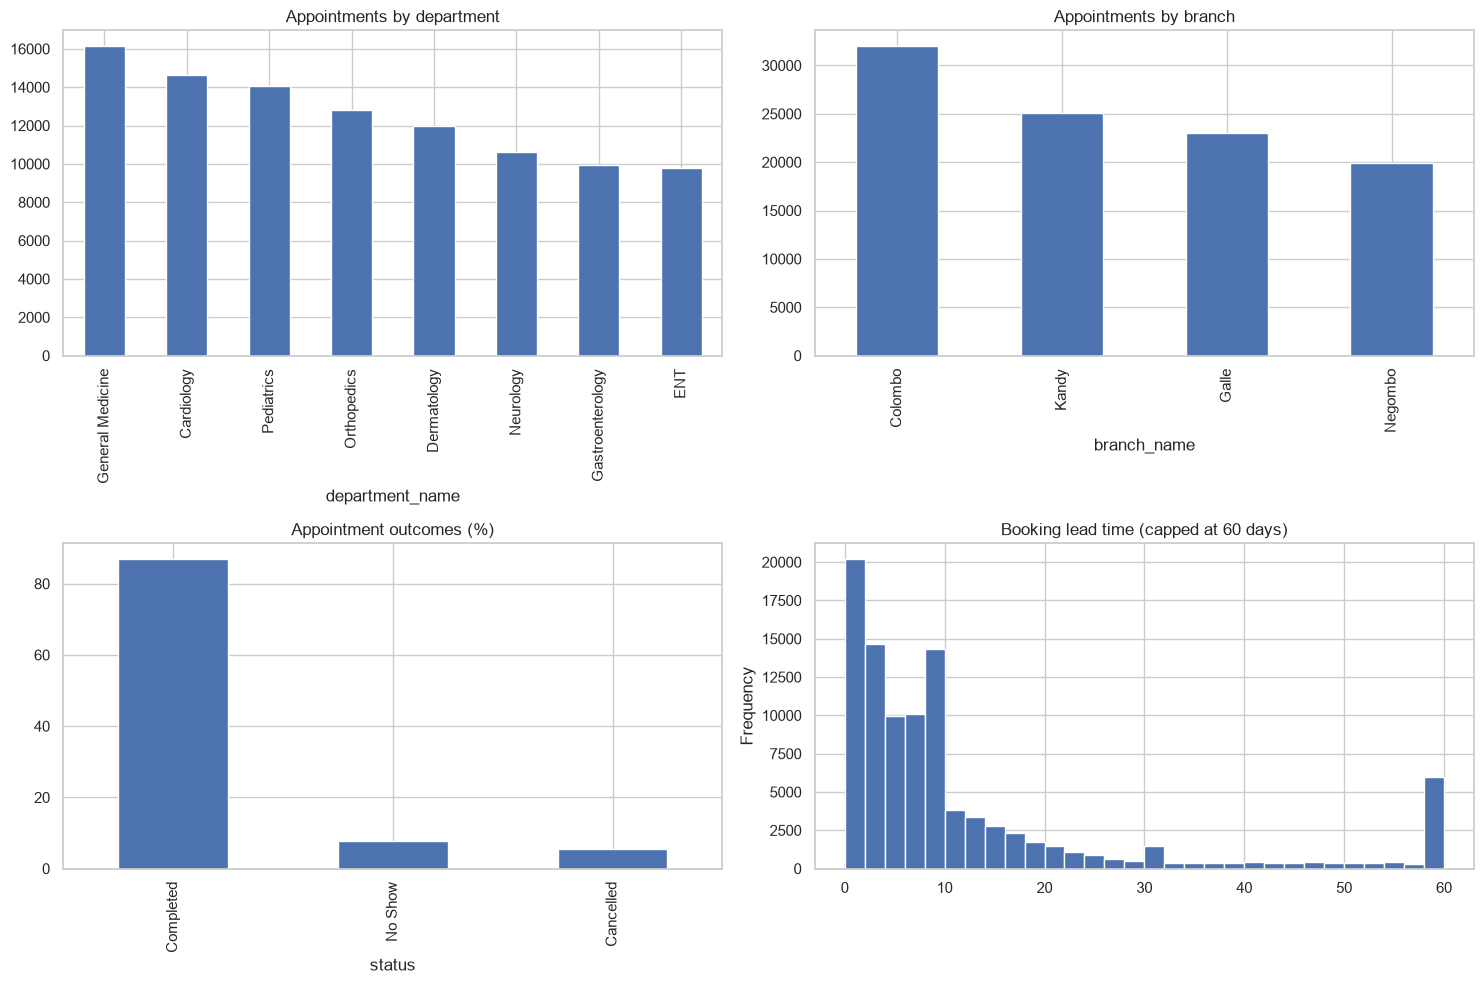

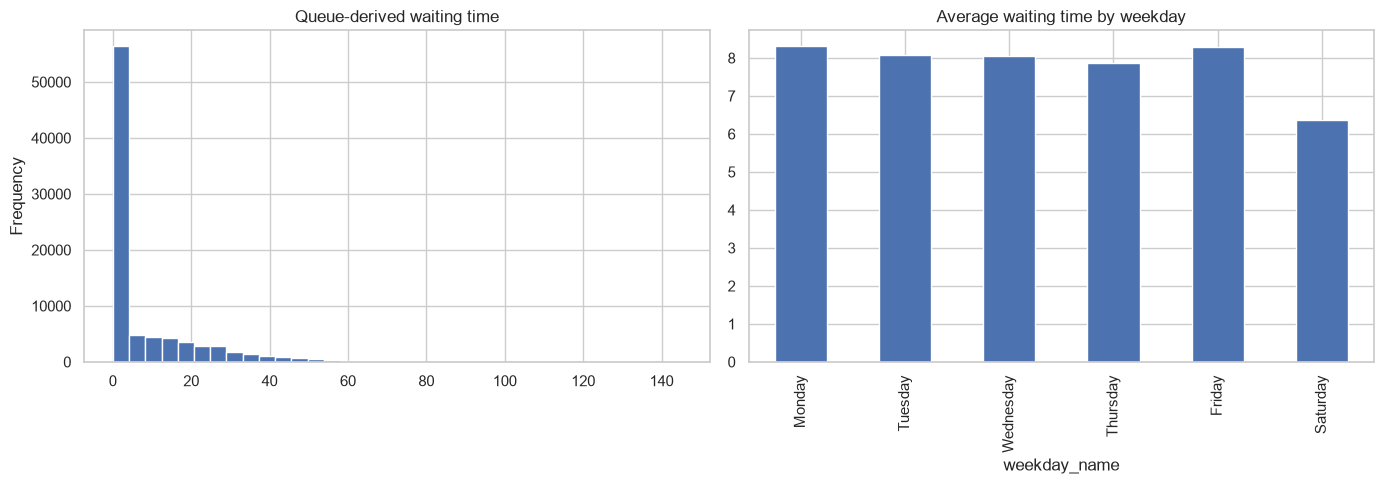

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
appointments_df.merge(departments_df[["department_id", "department_name"]], on="department_id").department_name.value_counts().plot(kind="bar", ax=axes[0,0], title="Appointments by department")
appointments_df.merge(branches_df[["branch_id", "branch_name"]], on="branch_id").branch_name.value_counts().plot(kind="bar", ax=axes[0,1], title="Appointments by branch")
appointments_df.status.value_counts(normalize=True).mul(100).plot(kind="bar", ax=axes[1,0], title="Appointment outcomes (%)")
appointments_df.lead_time_days.clip(upper=60).plot(kind="hist", bins=30, ax=axes[1,1], title="Booking lead time (capped at 60 days)")
plt.tight_layout()
plt.show()

completed_analysis = appointments_df.loc[appointments_df.status.eq("Completed")].copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
completed_analysis.waiting_time_minutes.astype(float).plot(kind="hist", bins=35, ax=axes[0], title="Queue-derived waiting time")
completed_analysis.groupby("weekday_name").waiting_time_minutes.mean().reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]).plot(kind="bar", ax=axes[1], title="Average waiting time by weekday")
plt.tight_layout()
plt.show()

## 14. Summary metrics for a first sanity check

In [14]:
summary = {
    "appointments": int(len(appointments_df)),
    "unique_patients_with_appointments": int(appointments_df.patient_id.nunique()),
    "doctors": int(len(doctors_df)),
    "departments": int(len(departments_df)),
    "branches": int(len(branches_df)),
    "completed_rate_pct": round(appointments_df.status.eq("Completed").mean()*100, 2),
    "cancelled_rate_pct": round(appointments_df.status.eq("Cancelled").mean()*100, 2),
    "no_show_rate_pct": round(appointments_df.status.eq("No Show").mean()*100, 2),
    "mean_lead_time_days": round(appointments_df.lead_time_days.mean(), 2),
    "mean_waiting_minutes_completed": round(appointments_df.loc[appointments_df.status.eq("Completed"), "waiting_time_minutes"].mean(), 2),
    "mean_consultation_minutes_completed": round(appointments_df.loc[appointments_df.status.eq("Completed"), "consultation_duration_minutes"].mean(), 2),
    "collected_revenue_lkr": round(payments_df.amount_collected_lkr.sum(), 2),
    "mean_satisfaction": round(satisfaction_df.satisfaction_score.mean(), 2),
}
print(json.dumps(summary, indent=2))

{
  "appointments": 100000,
  "unique_patients_with_appointments": 22205,
  "doctors": 32,
  "departments": 8,
  "branches": 4,
  "completed_rate_pct": 86.94,
  "cancelled_rate_pct": 5.39,
  "no_show_rate_pct": 7.66,
  "mean_lead_time_days": 12.69,
  "mean_waiting_minutes_completed": 8.0,
  "mean_consultation_minutes_completed": 23.1,
  "collected_revenue_lkr": 390477762.79,
  "mean_satisfaction": 4.32
}


## 15. Save synthetic datasets — never overwrite the original notebook or real data

The original flat CSV names are not reused. This prevents accidentally mixing the old synthetic data with the rebuilt tables. All files include a `data_provenance` label where applicable.

In [15]:
synthetic_tables = {
    "patients.csv": patients_df,
    "doctors.csv": doctors_df,
    "branches.csv": branches_df,
    "departments.csv": departments_df,
    "appointments.csv": appointments_df,
    "doctor_schedules.csv": slots_df,
    "payments.csv": payments_df,
    "satisfaction.csv": satisfaction_df,
}
for filename, frame in synthetic_tables.items():
    frame.to_csv(SYNTHETIC_DIR / filename, index=False)

metadata = {
    "project": "MedInsight Analytics",
    "dataset_type": "synthetic_simulation",
    "random_seed": RANDOM_SEED,
    "appointment_count": NUM_APPOINTMENTS,
    "date_start": START_DATE,
    "date_end": END_DATE,
    "currency": "LKR",
    "country_context": "Sri Lanka-inspired demonstration assumptions; not real hospital data",
    "tables": list(synthetic_tables.keys()),
    "warning": "Do not represent these simulated records or metrics as observed hospital facts."
}
with open(SYNTHETIC_DIR / "dataset_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Saved synthetic tables to:", SYNTHETIC_DIR)
for filename, frame in synthetic_tables.items():
    print(f"{filename:22s} {len(frame):>8,} rows")

Saved synthetic tables to: /Users/nethulinatharadhanapala/MedInsight-Analytics/data/raw/synthetic
patients.csv             25,000 rows
doctors.csv                  32 rows
branches.csv                  4 rows
departments.csv               8 rows
appointments.csv        100,000 rows
doctor_schedules.csv    142,692 rows
payments.csv             86,941 rows
satisfaction.csv         86,941 rows


## 16. Optional: prepare the real public no-show dataset separately

A useful real-world benchmark is the **Medical Appointment No Shows** dataset by Joni Hoppen on Kaggle (Brazil, 2016; approximately 110,527 appointments). It includes patient/booking fields and the `No-show` target, but it does **not** contain the doctor schedules, actual queue waiting times, consultation durations, branch operations or revenue needed for the full MedInsight operations dashboard.

Download it from the Kaggle page below (Kaggle may require an account), then place the original CSV in:

`data/raw/real/noshowappointments-kagglev2-may-2016.csv`

Keep the downloaded original file unchanged. This cell creates a separate cleaned analysis copy only if the file exists. Do not append it to the synthetic appointments table.

Source: https://www.kaggle.com/datasets/joniarroba/noshowappointments

In [16]:
REAL_CSV = REAL_DIR / "noshowappointments-kagglev2-may-2016.csv"

if REAL_CSV.exists():
    real_raw_df = pd.read_csv(REAL_CSV)
    print("Real source loaded:", real_raw_df.shape)
    print("Original columns:", real_raw_df.columns.tolist())

    # Standardise column names without changing the original downloaded file.
    real_df = real_raw_df.copy()
    real_df.columns = [c.strip().replace(" ", "_") for c in real_df.columns]
    required = {"PatientId", "AppointmentID", "Gender", "ScheduledDay", "AppointmentDay", "Age", "No-show"}
    missing = required - set(real_df.columns)
    if missing:
        raise ValueError(f"Expected columns missing from Kaggle file: {missing}")

    real_df["ScheduledDay"] = pd.to_datetime(real_df["ScheduledDay"], errors="coerce", utc=True).dt.tz_convert(None)
    real_df["AppointmentDay"] = pd.to_datetime(real_df["AppointmentDay"], errors="coerce", utc=True).dt.tz_convert(None)
    real_df["lead_time_days"] = (real_df["AppointmentDay"].dt.normalize() - real_df["ScheduledDay"].dt.normalize()).dt.days
    real_df["no_show"] = real_df["No-show"].astype(str).str.strip().str.lower().eq("yes").astype(int)
    real_df["data_provenance"] = "REAL_PUBLIC_DATA_BRAZIL_2016"

    # Flag questionable date/age records; do not silently discard them.
    real_df["date_order_valid"] = real_df.lead_time_days.ge(0)
    real_df["age_valid"] = real_df.Age.between(0, 110)
    real_df.to_csv(PROCESSED_REAL_DIR / "real_no_show_prepared.csv", index=False)
    print("Prepared real-data copy saved separately:", PROCESSED_REAL_DIR / "real_no_show_prepared.csv")
    display(real_df[["PatientId", "AppointmentID", "Age", "lead_time_days", "no_show", "date_order_valid", "age_valid"]].head())
else:
    print("Real Kaggle CSV not found yet.")
    print("Download it and place it at:", REAL_CSV)
    real_raw_df = None
    real_df = None

Real Kaggle CSV not found yet.
Download it and place it at: /Users/nethulinatharadhanapala/MedInsight-Analytics/data/raw/real/noshowappointments-kagglev2-may-2016.csv


## 17. Compare provenance — keep the analyses separate

Use the real dataset to explore no-show patterns and test attendance models on real historical clinic data. Use synthetic tables to demonstrate hospital operations analytics, queueing, branch/doctor capacity, revenue and dashboards. Model performance on synthetic data is not evidence of real-world predictive performance.

In [17]:
print("SYNTHETIC source:", SYNTHETIC_DIR)
print("REAL source:", REAL_DIR)
print("PROCESSED REAL copy:", PROCESSED_REAL_DIR)
print("Synthetic appointment rows:", len(appointments_df))
if real_df is not None:
    print("Real public appointment rows:", len(real_df))
    print("Real public no-show rate (%):", round(real_df.no_show.mean()*100, 2))
else:
    print("Real dataset has not been added yet; no real-data metrics calculated.")

SYNTHETIC source: /Users/nethulinatharadhanapala/MedInsight-Analytics/data/raw/synthetic
REAL source: /Users/nethulinatharadhanapala/MedInsight-Analytics/data/raw/real
PROCESSED REAL copy: /Users/nethulinatharadhanapala/MedInsight-Analytics/data/processed/real
Synthetic appointment rows: 100000
Real dataset has not been added yet; no real-data metrics calculated.


## 18. Interpretation and limitations

1. **Synthetic is not real:** all synthetic records, outcomes, waiting times, tariffs, satisfaction and revenue are simulated.
2. **Assumptions require calibration:** branch demand, department shares, no-show probabilities, doctor capacity and tariffs are illustrative. If a hospital provides approved anonymised data, estimate these from that source.
3. **Queue model is simplified:** it models one doctor serving appointments sequentially. It does not yet model nurses, lab delays, emergencies, walk-ins, room constraints or multiple consultation rooms.
4. **No clinical inference:** visit reasons are broad synthetic operational labels, not diagnoses or medical advice.
5. **Real benchmark scope:** the Brazil public dataset is geographically and operationally different from Sri Lankan private hospitals. Treat it as a no-show research benchmark, not a local validation dataset.
6. **Privacy:** never use identifiable patient data in a public portfolio. Use approved anonymised data or synthetic data only.

### Recommended next notebook
`02_data_cleaning_and_eda.ipynb`: load these tables, inspect distributions and outliers, create operational KPIs, and document each metric's numerator/denominator.